In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from imblearn.over_sampling import RandomOverSampler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt
import numpy as np

In [6]:
import os
os.chdir(os.path.expanduser('~/Desktop'))

import pandas as pd
df_train = pd.read_parquet('P03_train.pq')
df_test = pd.read_parquet('P03_test.pq')

In [ ]:
#from pathlib import Path #alternative to the os above
#desktop = Path.home() / 'Desktop'
#df_train = pd.read_parquet(desktop / 'P03_train.pq')
#df_test = pd.read_parquet(desktop / 'P03_test.pq')

In [11]:
df_test_ids = df_test['id'].copy()

In [7]:
df_train.head()

,id,flag,pre_since_opened,pre_since_confirmed,pre_pterm,pre_fterm,pre_till_pclose,pre_till_fclose,pre_loans_credit_limit,pre_loans_next_pay_summ,...,enc_paym_21,enc_paym_22,enc_paym_23,enc_paym_24,enc_loans_account_holder_type,enc_loans_credit_status,enc_loans_credit_type,enc_loans_account_cur,pclose_flag,fclose_flag
0,41794,0,3,9,16,9,15,14,16,3,...,3,3,3,4,1,3,4,1,0,0
1,160704,0,9,6,0,1,0,4,1,3,...,3,3,3,4,1,2,3,1,0,0
2,41771,0,12,16,14,8,10,11,10,2,...,3,3,3,4,1,2,3,1,0,1
3,160727,0,7,9,17,16,14,8,14,3,...,3,3,3,4,1,2,4,1,0,0
4,160729,0,9,9,4,8,1,11,10,3,...,3,3,3,4,1,2,3,1,1,1


In [5]:
df_train = df_train.drop(columns=["id", "pre_loans_total_overdue", "pre_loans6090", 'pre_loans5', 'pre_loans530', 'pre_loans3060', 'pre_loans90', "enc_loans_account_cur", "enc_loans_account_holder_type" ])
df_test = df_test.drop(columns=["id", "pre_loans_total_overdue", "pre_loans6090", 'pre_loans5', 'pre_loans530', 'pre_loans3060', 'pre_loans90', "enc_loans_account_cur", "enc_loans_account_holder_type" ])

In [13]:
paym_cols = [c for c in df_train.columns if c.startswith('enc_paym_')]

for df in [df_train, df_test]:
    df['paym_mean'] = df[paym_cols].mean(axis=1)
    df['paym_std'] = df[paym_cols].std(axis=1)
    df['paym_nonzero_count'] = (df[paym_cols] > 0).sum(axis=1)

In [14]:
target = "flag"
X = df_train.drop(columns=[target])
y = df_train[target]


print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (175000, 54)
y shape: (175000,)


In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (140000, 54)
y_train shape: (140000,)
X_test shape: (35000, 54)
y_test shape: (35000,)


In [16]:
over_sampler = RandomOverSampler(random_state=42)
X_train_over, y_train_over = over_sampler.fit_resample(X_train, y_train)
print("X_train_over shape:", X_train_over.shape)
X_train_over.head()

X_train_over shape: (271318, 54)


,pre_since_opened,pre_since_confirmed,pre_pterm,pre_fterm,pre_till_pclose,pre_till_fclose,pre_loans_credit_limit,pre_loans_next_pay_summ,pre_loans_outstanding,pre_loans_max_overdue_sum,...,enc_paym_22,enc_paym_23,enc_paym_24,enc_loans_credit_status,enc_loans_credit_type,pclose_flag,fclose_flag,paym_mean,paym_std,paym_nonzero_count
0,9,9,6,1,0,4,9,3,5,2,...,3,3,4,2,3,0,0,1.92,1.630951,15
1,19,9,1,16,14,8,14,0,1,2,...,3,3,4,2,4,0,0,2.88,0.927362,23
2,19,2,11,8,14,11,8,2,5,2,...,3,3,4,2,4,0,1,2.52,1.326650,20
3,12,10,15,8,12,11,16,3,2,2,...,3,3,4,2,4,0,1,2.88,0.927362,23
4,11,3,12,15,7,2,8,3,3,2,...,3,3,4,3,4,0,0,2.40,1.414214,19


In [17]:
import optuna
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 300),
        'max_depth': trial.suggest_int('max_depth', 3, 6),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 1.0),
        'num_leaves': trial.suggest_int('num_leaves', 15, 63),
        'random_state': 42
    }
    
    clf = lgb.LGBMClassifier(**params, verbose=-1)
    clf.fit(X_train_over, y_train_over)
    
    proba = clf.predict_proba(X_test)[:, 1]
    return roc_auc_score(y_test, proba)

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30)

print("Best params:", study.best_params)
print("Best ROC-AUC:", study.best_value)

[I 2026-07-06 00:13:02,774] A new study created in memory with name: no-name-00976fb3-4e33-494b-9a83-44c42d57b6bc
[I 2026-07-06 00:13:04,118] Trial 0 finished with value: 0.6957524877523166 and parameters: {'n_estimators': 123, 'max_depth': 5, 'learning_rate': 0.021259857472774587, 'subsample': 0.8810948525505625, 'colsample_bytree': 0.7053917908367011, 'num_leaves': 45}. Best is trial 0 with value: 0.6957524877523166.
[I 2026-07-06 00:13:05,792] Trial 1 finished with value: 0.6996568134894026 and parameters: {'n_estimators': 157, 'max_depth': 5, 'learning_rate': 0.05278137539040701, 'subsample': 0.9835538340656831, 'colsample_bytree': 0.710721402573295, 'num_leaves': 55}. Best is trial 1 with value: 0.6996568134894026.
[I 2026-07-06 00:13:07,249] Trial 2 finished with value: 0.6942485924760396 and parameters: {'n_estimators': 125, 'max_depth': 6, 'learning_rate': 0.01423355317187824, 'subsample': 0.7433730344306169, 'colsample_bytree': 0.8663904460182676, 'num_leaves': 24}. Best is tr

Best params: {'n_estimators': 236, 'max_depth': 3, 'learning_rate': 0.06860044234549073, 'subsample': 0.7680039882647988, 'colsample_bytree': 0.9787785351731384, 'num_leaves': 35}
Best ROC-AUC: 0.7054827907393858


In [18]:
from sklearn.metrics import classification_report, roc_auc_score

best_clf_lgb = lgb.LGBMClassifier(**study.best_params, random_state=42, verbose=-1)
best_clf_lgb.fit(X_train_over, y_train_over)

print("=== Train (oversampled) ===")
print(classification_report(y_train_over, best_clf_lgb.predict(X_train_over)))
print("ROC-AUC (train):", roc_auc_score(y_train_over, best_clf_lgb.predict_proba(X_train_over)[:, 1]))

print("\n=== Test (original) ===")
print(classification_report(y_test, best_clf_lgb.predict(X_test)))
print("ROC-AUC (test):", roc_auc_score(y_test, best_clf_lgb.predict_proba(X_test)[:, 1]))

=== Train (oversampled) ===
              precision    recall  f1-score   support

           0       0.67      0.67      0.67    135659
           1       0.67      0.67      0.67    135659

    accuracy                           0.67    271318
   macro avg       0.67      0.67      0.67    271318
weighted avg       0.67      0.67      0.67    271318

ROC-AUC (train): 0.7378366656861157

=== Test (original) ===
              precision    recall  f1-score   support

           0       0.98      0.67      0.80     33915
           1       0.06      0.63      0.11      1085

    accuracy                           0.67     35000
   macro avg       0.52      0.65      0.45     35000
weighted avg       0.95      0.67      0.78     35000

ROC-AUC (test): 0.7054827907393858


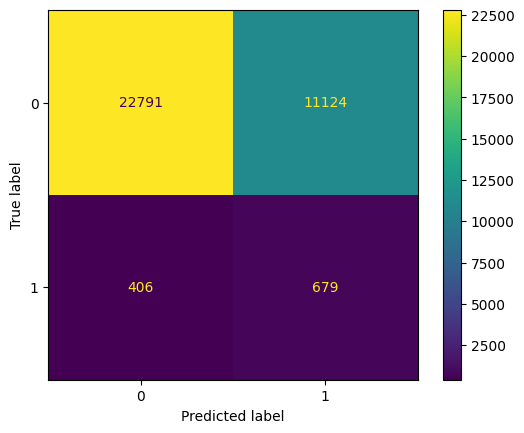

In [19]:
ConfusionMatrixDisplay.from_estimator(best_clf_lgb, X_test, y_test)

In [20]:
test_proba = best_clf_lgb.predict_proba(df_test)[:, 1]

In [23]:
submission = pd.DataFrame({
    'id': df_test_ids,
    'flag_proba': test_proba
})

submission.to_csv('predictions.csv', index=False)
print(f"Saved {len(submission)} predictions to predictions.csv")
print(submission.head())

Saved 75000 predictions to predictions.csv
       id  flag_proba
0  225096    0.239040
1  220040    0.514579
2   26535    0.564734
3   77272    0.751977
4  193584    0.523337


In [24]:
submission = pd.DataFrame({
    'id': df_test_ids,
    'flag_proba': test_proba
})

submission.to_parquet('predictions.pq', index=False)
print(f"Saved {len(submission)} predictions to predictions.pq")
submission.head()

Saved 75000 predictions to predictions.pq


,id,flag_proba
0,225096,0.239040
1,220040,0.514579
2,26535,0.564734
3,77272,0.751977
4,193584,0.523337
